# Дизайн эксперимента: блок «Похожие вакансии» после отклика

Данные лежат в папке `data/` рядом с ноутбуком. Все случайные разбиения с фиксированным seed.

In [1]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)

SEED = 2027
ALPHA = 0.05
POWER = 0.8
TARGET_THR = 1.7 # окупаемость, %
GUARD_THR = 3.0 # допустимое падение приглашений, %

m = pd.read_csv('data/user_week_metrics.csv')
u = pd.read_csv('data/users.csv')
print(m.shape, u.shape)

(870685, 10) (388000, 6)


## 1. Постановка

Гипотеза: после отклика показываем 3–5 похожих вакансий с откликом в один клик. Соискателю становится дешевле найти и отправить ещё отклики на подходящие вакансии, растёт число откликов, на которые работодатель реагирует, и вместе с ним растут релевантные отклики на соискателя.

| Корзина | Метрика | Тест | α |
|---|---|---|---|
| Целевая | релевантные отклики на соискателя | двусторонний | 0.05 |
| Guardrail | приглашения на соискателя | односторонний (тест хуже контроля) | 0.05 |
| Информационная | отклики на соискателя | двусторонний | 0.001 |
| Информационная | доля релевантных среди откликов | двусторонний | 0.001 |
| Информационная | показы блока, отклики из блока на соискателя, CTR блока | двусторонний | 0.001 |
| Информационная | полученные отклики, доля релевантных и приглашения на работодателя | двусторонний | 0.001 |

Единица рандомизации — соискатель (user_id). Популяция анализа — соискатели, у которых в период теста был trigger event: первый отклик, после которого блок показан (в тесте) или был бы показан (в контроле).

## 2. Качество данных

In [2]:
A = ['vacancy_views_app', 'responses_app', 'relevant_responses_app', 'invitations_app']
E = ['responses_emp', 'relevant_responses_emp', 'invitations_emp']
app = m[m.user_type == 'APPLICANT']
emp = m[m.user_type == 'EMPLOYER']

checks = {
    'дубли строк (неделя, пользователь)': m.duplicated(['week_start', 'user_id']).sum(),
    'дубли user_id в справочнике': u.user_id.duplicated().sum(),
    'пользователи метрик вне справочника': (~m.user_id.isin(u.user_id)).sum(),
    'тип пользователя не совпадает со справочником': (m.merge(u[['user_id', 'user_type']], on='user_id').pipe(lambda d: d.user_type_x != d.user_type_y)).sum(),
    'пропуски в метриках соискателя у соискателей': app[A].isna().sum().sum(),
    'заполненные метрики работодателя у соискателей': app[E].notna().sum().sum(),
    'отрицательные значения': (m[A + E] < 0).sum().sum(),
    'релевантных больше, чем откликов': (app.relevant_responses_app > app.responses_app).sum(),
    'приглашений больше, чем релевантных': (app.invitations_app > app.relevant_responses_app).sum(),
    'откликов больше, чем просмотров вакансий': (app.responses_app > app.vacancy_views_app).sum(),
    'строки соискателей без единого действия': (app[A].sum(axis=1) == 0).sum(),
}
for k, v in checks.items():
    print(f'{k:50s} {v}')

дубли строк (неделя, пользователь)                 0
дубли user_id в справочнике                        0
пользователи метрик вне справочника                0
тип пользователя не совпадает со справочником      0
пропуски в метриках соискателя у соискателей       0
заполненные метрики работодателя у соискателей     0
отрицательные значения                             0
релевантных больше, чем откликов                   0
приглашений больше, чем релевантных                0
откликов больше, чем просмотров вакансий           7686
строки соискателей без единого действия            753


In [3]:
weekly = app.groupby('week_start').agg(
    applicants=('user_id', 'size'),
    with_response=('responses_app', lambda s: (s > 0).sum()),
    views=('vacancy_views_app', 'mean'),
    responses=('responses_app', 'mean'),
    relevant=('relevant_responses_app', 'mean'),
    invitations=('invitations_app', 'mean'),
)
weekly['share_with_response'] = weekly.with_response / weekly.applicants
weekly['employers'] = emp.groupby('week_start').size()
print(weekly.round(3))

            applicants  with_response   views  responses  relevant  invitations  share_with_response  employers
week_start                                                                                                     
2026-03-09      102701          94675  28.928      5.342     2.691        0.330                0.922       5361
2026-03-16      103872          95857  28.719      5.289     2.670        0.329                0.923       5358
2026-03-23      103090          95082  28.748      5.326     2.702        0.332                0.922       5312
2026-03-30      101859          93844  28.981      5.329     2.695        0.331                0.921       5344
2026-04-06      102791          94868  29.020      5.342     2.692        0.331                0.923       5364
2026-04-13      103926          95994  29.108      5.374     2.723        0.333                0.924       5241
2026-04-20      102599          94635  28.833      5.317     2.681        0.329                0.922    

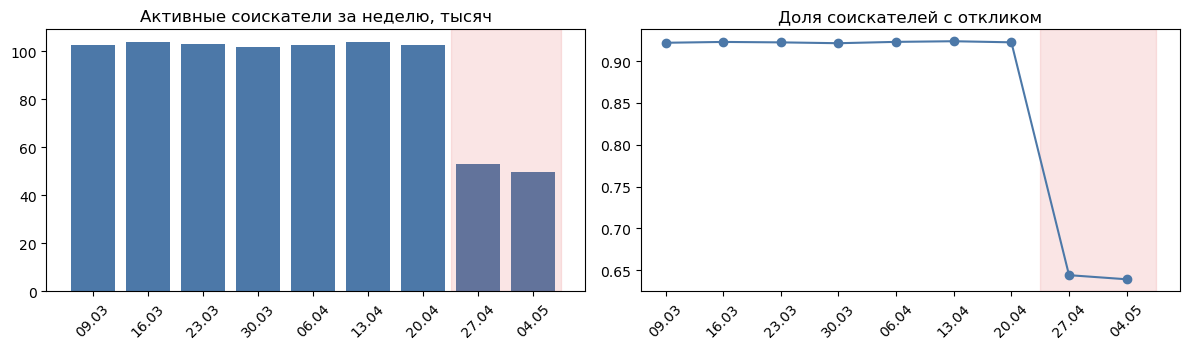

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
x = pd.to_datetime(weekly.index).strftime('%d.%m')
ax[0].bar(x, weekly.applicants / 1000, color='#4C78A8')
ax[0].set_title('Активные соискатели за неделю, тысяч')
ax[1].plot(x, weekly.share_with_response, marker='o', color='#4C78A8')
ax[1].set_title('Доля соискателей с откликом')
for a_ in ax:
    a_.tick_params(axis='x', rotation=45)
    a_.axvspan(6.5, 8.5, color='#E45756', alpha=0.15)
plt.tight_layout()
plt.show()

In [5]:
reg = pd.to_datetime(u.reg_date)
print('reg_date: min', reg.min().date(), 'max', reg.max().date())
x = app.merge(u[['user_id', 'reg_date']], on='user_id')
x['age_days'] = (pd.to_datetime(x.week_start) - pd.to_datetime(x.reg_date)).dt.days
print('доля соискателей, зарегистрированных менее 30 дней назад:')
print(x.groupby('week_start').age_days.apply(lambda s: round((s < 30).mean(), 3)).to_string())

reg_date: min 2017-12-22 max 2026-03-09
доля соискателей, зарегистрированных менее 30 дней назад:
week_start
2026-03-09    0.131
2026-03-16    0.100
2026-03-23    0.069
2026-03-30    0.038
2026-04-06    0.009
2026-04-13    0.000
2026-04-20    0.000
2026-04-27    0.000
2026-05-04    0.000


In [6]:
print(app[A].quantile([0.5, 0.9, 0.99, 0.999, 1]).round(1))
heavy = app.responses_app > 100
print('строк с > 100 откликов в неделю:', heavy.sum(), ', пользователей:', app[heavy].user_id.nunique())
share_rel = app.relevant_responses_app / app.responses_app
print('медианная доля релевантных: > 100 откликов', round(share_rel[heavy].median(), 3),
      '| остальные с откликом', round(share_rel[~heavy & (app.responses_app > 0)].median(), 3))

       vacancy_views_app  responses_app  relevant_responses_app  invitations_app
0.500               20.0            3.0                     2.0              0.0
0.900               55.0           10.0                     6.0              1.0
0.990              157.0           35.0                    15.0              4.0
0.999              629.5          156.0                    35.0              8.0
1.000             7388.0         1680.0                   244.0             60.0
строк с > 100 откликов в неделю: 2022 , пользователей: 627
медианная доля релевантных: > 100 откликов 0.151 | остальные с откликом 0.545


Выводы по качеству данных:
- Структура корректна: нет дублей, все пользователи есть в справочнике, типы совпадают, вложенность «приглашения ⊆ релевантные ⊆ отклики» выполняется. Отклики без просмотров возможны (отклик из выдачи), строки без действий — заход без активности; это не ошибки.
- Недели 27.04 и 04.05 — майские праздники 2026 года (1–3 и 9–11 мая): соискателей вдвое меньше, доля с откликом 64% вместо 92%. Для прогноза не подходят.
- Неделя 09.03 начинается с выходного дня 9 марта (перенос с 8 марта). Метрики в ней не отличаются от соседних, но базовым берём окно без праздников: 16.03–19.04 (5 полных рабочих недель). Остальные окна проверяем на устойчивость.
- Справочник не содержит регистраций позже 09.03.2026, поэтому в истории нет новых пользователей: доля зарегистрированных менее 30 дней назад падает с 13% до 0. В реальном тесте новые пользователи будут приходить, выборка за 2–5 недель будет больше, чем в истории, поэтому оценка MDE для длинных сроков консервативна.
- Тяжёлый хвост: до 1680 откликов в неделю, у пользователей с > 100 откликами доля релевантных около 15% против 55% у остальных (похоже на массовые автоотклики). Из метрики их не убираем: они будут и в тесте. Они увеличивают дисперсию; ниже показано, сколько дало бы ограничение по 99.9-му перцентилю.

## 3. MDE по данным

Метрика на пользователя: сумма релевантных откликов (для guardrail — приглашений) за все недели окна длиной k. Популяция: соискатели, у которых за окно был хотя бы один отклик (аналог trigger event). Размер группы n = N / 2 при сплите 50/50. Данные недельные, момент первого отклика неизвестен, поэтому в метрику попадает и активность до trigger event; в тесте считаем так же, одинаково для обеих групп.

MDE% = (z₁₋α/₂ + z₁₋β) · σ · √(2/n) / ȳ · 100%; для guardrail вместо z₁₋α/₂ берём z₁₋α (односторонний тест).

In [7]:
weeks = sorted(app.week_start.unique())
clean = [w for w in weeks if w < '2026-04-27']      # без майских недель
BASE = '2026-03-16'

Z = {'relevant_responses_app': stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER),
     'invitations_app': stats.norm.ppf(1 - ALPHA) + stats.norm.ppf(POWER),
     'responses_app': stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)}

def window(start, k):
    w = clean[clean.index(start): clean.index(start) + k]
    assert len(w) == k
    d = app[app.week_start.isin(w)].groupby('user_id')[['responses_app', 'relevant_responses_app', 'invitations_app']].sum()
    return d[d.responses_app > 0]

def mde(x, z):
    n = len(x) / 2
    return z * x.std(ddof=1) * np.sqrt(2 / n) / x.mean() * 100

rows = []
for start in clean:
    for k in range(1, 6):
        if clean.index(start) + k > len(clean):
            continue
        d = window(start, k)
        r = {'start': start, 'weeks': k, 'n_group': len(d) // 2}
        for col in Z:
            r[col] = mde(d[col], Z[col])
            r[col + '_mean'] = d[col].mean()
            r[col + '_cv'] = d[col].std(ddof=1) / d[col].mean()
        r['relevant_capped'] = mde(d.relevant_responses_app.clip(upper=d.relevant_responses_app.quantile(0.999)), Z['relevant_responses_app'])
        r['invitations_capped'] = mde(d.invitations_app.clip(upper=d.invitations_app.quantile(0.999)), Z['invitations_app'])
        rows.append(r)
grid = pd.DataFrame(rows)

base = grid[grid.start == BASE].set_index('weeks')
print(base[['n_group', 'relevant_responses_app', 'invitations_app', 'responses_app', 'relevant_capped', 'invitations_capped']].round(2))

       n_group  relevant_responses_app  invitations_app  responses_app  relevant_capped  invitations_capped
weeks                                                                                                      
1        47928                    1.88             3.77           3.26             1.81                3.68
2        78160                    1.64             3.01           2.98             1.58                2.89
3        98879                    1.58             2.74           2.99             1.50                2.62
4       114142                    1.55             2.60           3.04             1.45                2.45
5       125929                    1.53             2.50           3.03             1.42                2.34


In [8]:
spread = grid.groupby('weeks')[['relevant_responses_app', 'invitations_app']].agg(['min', 'max', 'count']).round(2)
print('MDE% по всем окнам без праздников:')
print(spread)

MDE% по всем окнам без праздников:
      relevant_responses_app             invitations_app            
                         min   max count             min   max count
weeks                                                               
1                       1.86  1.97     7            3.72  3.90     7
2                       1.64  1.73     6            3.01  3.12     6
3                       1.58  1.64     5            2.74  2.81     5
4                       1.55  1.59     4            2.60  2.66     4
5                       1.53  1.54     3            2.50  2.53     3


In [9]:
print(base[['n_group', 'relevant_responses_app_mean', 'relevant_responses_app_cv', 'invitations_app_mean', 'invitations_app_cv']].round(3))
print('рост n к первой неделе:', (base.n_group / base.n_group.iloc[0]).round(2).tolist())

       n_group  relevant_responses_app_mean  relevant_responses_app_cv  invitations_app_mean  invitations_app_cv
weeks                                                                                                           
1        47928                        2.893                      1.039                 0.356               2.345
2        78160                        3.556                      1.158                 0.437               2.391
3        98879                        4.199                      1.252                 0.516               2.446
4       114142                        4.849                      1.323                 0.596               2.502
5       125929                        5.519                      1.366                 0.678               2.524
рост n к первой неделе: [1.0, 1.63, 2.06, 2.38, 2.63]


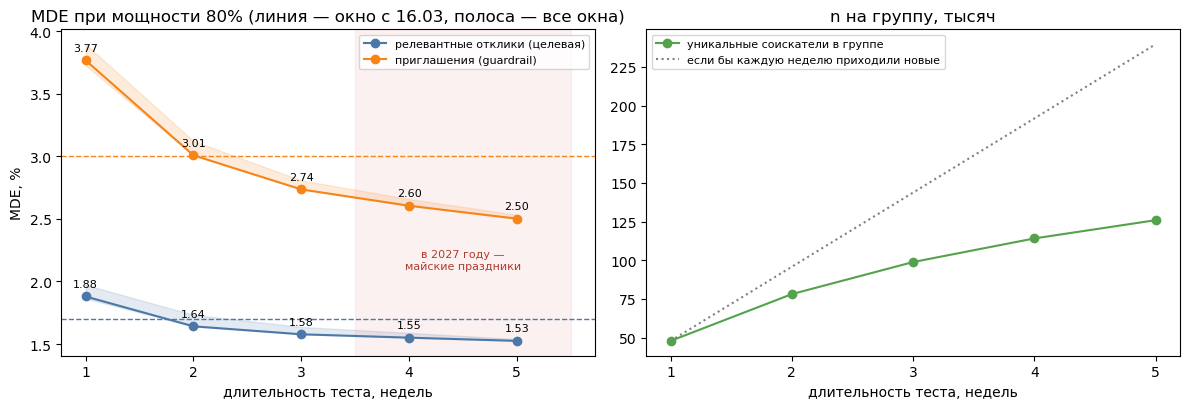

In [10]:
lo = grid.groupby('weeks')[['relevant_responses_app', 'invitations_app']].min()
hi = grid.groupby('weeks')[['relevant_responses_app', 'invitations_app']].max()
k = base.index

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for col, thr, color, name in [('relevant_responses_app', TARGET_THR, '#4C78A8', 'релевантные отклики (целевая)'),
                              ('invitations_app', GUARD_THR, '#F58518', 'приглашения (guardrail)')]:
    ax[0].fill_between(k, lo[col], hi[col], color=color, alpha=0.15)
    ax[0].plot(k, base[col], marker='o', color=color, label=name)
    ax[0].axhline(thr, color=color, ls='--', lw=1)
    for kk, v in base[col].items():
        ax[0].annotate(f'{v:.2f}', (kk, v), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
ax[0].axvspan(3.5, 5.5, color='#E45756', alpha=0.08)
ax[0].text(4.5, 2.1, 'в 2027 году —\nмайские праздники', ha='center', fontsize=8, color='#B03A2E')
ax[0].set_xlabel('длительность теста, недель')
ax[0].set_ylabel('MDE, %')
ax[0].set_title('MDE при мощности 80% (линия — окно с 16.03, полоса — все окна)')
ax[0].legend(fontsize=8)

ax[1].plot(k, base.n_group / 1000, marker='o', color='#54A24B', label='уникальные соискатели в группе')
ax[1].plot(k, base.n_group.iloc[0] * k / 1000, ls=':', color='grey', label='если бы каждую неделю приходили новые')
ax[1].set_xlabel('длительность теста, недель')
ax[1].set_xticks(k)
ax[1].set_title('n на группу, тысяч')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Форма графика: MDE падает быстро от 1 к 2 неделям и почти перестаёт падать после 3-й.
- MDE% пропорционален CV / √n, где CV = σ / ȳ.
- n растёт медленнее линейного: те же соискатели возвращаются, прирост за неделю уменьшается (+63%, +27%, +15%, +10%).
- Метрика с каждой неделей другая: сумма за k недель. Её CV растёт с 1.04 до 1.37 для релевантных откликов: активные пользователи накапливают отклики быстрее остальных, разброс растёт быстрее среднего. Это уменьшает выигрыш от роста n.
- Полоса по разным окнам узкая: оценка устойчива к выбору периода.

## 4. Длительность

In [11]:
table = base[['n_group', 'relevant_responses_app', 'invitations_app']].copy()
table['target_ok'] = table.relevant_responses_app <= TARGET_THR
table['guard_ok'] = table.invitations_app <= GUARD_THR
table['target_ok_all_windows'] = hi.relevant_responses_app <= TARGET_THR
table['guard_ok_all_windows'] = hi.invitations_app <= GUARD_THR
print(table.round(2))

       n_group  relevant_responses_app  invitations_app  target_ok  guard_ok  target_ok_all_windows  guard_ok_all_windows
weeks                                                                                                                    
1        47928                    1.88             3.77      False     False                  False                 False
2        78160                    1.64             3.01       True     False                  False                 False
3        98879                    1.58             2.74       True      True                   True                  True
4       114142                    1.55             2.60       True      True                   True                  True
5       125929                    1.53             2.50       True      True                   True                  True


Срок — 3 недели: с понедельника 5 апреля по воскресенье 25 апреля 2027 года.
- 2 недели не хватает: MDE guardrail 3.01% больше порога 3%, а MDE целевой метрики по разным окнам доходит до 1.73% при пороге 1.7%.
- 3 недели — минимальный срок, при котором оба порога выполняются во всех окнах: целевая 1.58% (1.58–1.64%), guardrail 2.74% (2.74–2.81%).
- 4-я и 5-я недели попадают на майские праздники и уменьшают MDE целевой метрики всего на 0.03–0.05 процентного пункта.
- 21 день кратен недельному циклу.

Продакту: если релевантные отклики на соискателя вырастут на 1.6% и больше, тест это заметит с вероятностью 80%; порог окупаемости 1.7% покрыт. Падение приглашений на соискателя на 2.7% и больше заметим с вероятностью 80%; стоп-порог 3% покрыт.

## 5. A/A на истории

In [12]:
d3 = window(BASE, 3)
y = d3.relevant_responses_app.to_numpy(dtype=float)
g = d3.invitations_app.to_numpy(dtype=float)
N = len(y)
rng = np.random.default_rng(SEED)
N_RUNS = 5000

def welch_p(x, mask, shift=0.0, two_sided=True):
    a_, b_ = x[~mask], x[mask] + shift
    se = np.sqrt(a_.var(ddof=1) / len(a_) + b_.var(ddof=1) / len(b_))
    t = (b_.mean() - a_.mean()) / se
    return 2 * stats.norm.sf(abs(t)) if two_sided else stats.norm.cdf(t)

d_rel = TARGET_THR / 100 * y.mean()
d_inv = -GUARD_THR / 100 * g.mean()
p_aa, p_aa_g, p_srm, p_pow, p_pow_g = [], [], [], [], []
for _ in range(N_RUNS):
    mask = rng.random(N) < 0.5
    p_aa.append(welch_p(y, mask))
    p_aa_g.append(welch_p(g, mask, two_sided=False))
    p_srm.append(stats.chisquare([(~mask).sum(), mask.sum()]).pvalue)
    p_pow.append(welch_p(y, mask, shift=d_rel))
    p_pow_g.append(welch_p(g, mask, shift=d_inv, two_sided=False))
p_aa, p_aa_g, p_srm, p_pow, p_pow_g = map(np.array, (p_aa, p_aa_g, p_srm, p_pow, p_pow_g))

def share_ci(p, thr=0.05):
    s = (p < thr).mean()
    half = 1.96 * np.sqrt(s * (1 - s) / len(p))
    return f'{s:.3f} [{s - half:.3f}, {s + half:.3f}]'

print('N =', N, ', запусков:', N_RUNS)
print('A/A, релевантные отклики, доля p < 0.05:', share_ci(p_aa))
print('A/A, приглашения (односторонний), доля p < 0.05:', share_ci(p_aa_g))
print('SRM по всем запускам, доля p < 0.001:', (p_srm < 0.001).mean())
print('KS-тест равномерности p-value A/A: p =', round(stats.kstest(p_aa, 'uniform').pvalue, 3))
print(f'мощность при +{TARGET_THR}% к релевантным откликам:', round((p_pow < 0.05).mean(), 3))
print(f'мощность при -{GUARD_THR}% к приглашениям:', round((p_pow_g < 0.05).mean(), 3))

N = 197758 , запусков: 5000
A/A, релевантные отклики, доля p < 0.05: 0.048 [0.042, 0.054]
A/A, приглашения (односторонний), доля p < 0.05: 0.046 [0.041, 0.052]
SRM по всем запускам, доля p < 0.001: 0.0014
KS-тест равномерности p-value A/A: p = 0.513
мощность при +1.7% к релевантным откликам: 0.853
мощность при -3.0% к приглашениям: 0.862


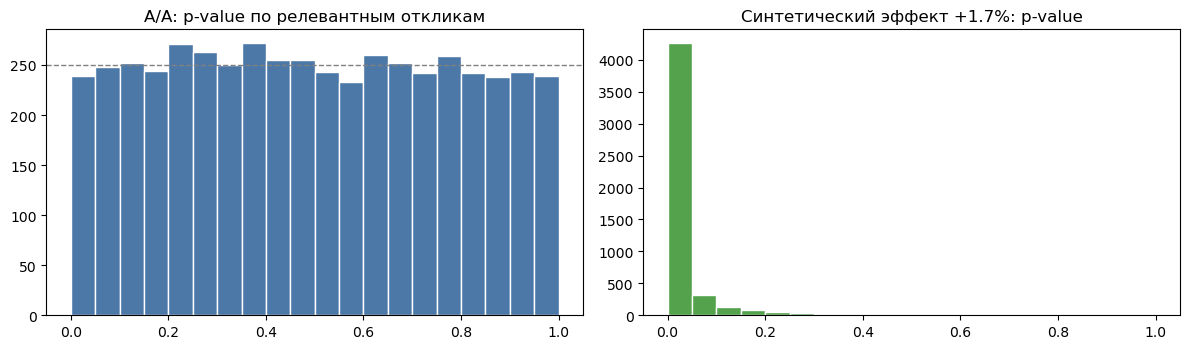

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(p_aa, bins=20, range=(0, 1), color='#4C78A8', edgecolor='white')
ax[0].axhline(N_RUNS / 20, color='grey', ls='--', lw=1)
ax[0].set_title('A/A: p-value по релевантным откликам')
ax[1].hist(p_pow, bins=20, range=(0, 1), color='#54A24B', edgecolor='white')
ax[1].set_title(f'Синтетический эффект +{TARGET_THR}%: p-value')
plt.tight_layout()
plt.show()

In [14]:
salt = 'similar_vacancies_2027'
grp = np.array([int(hashlib.md5(f'{salt}:{uid}'.encode()).hexdigest(), 16) % 2 for uid in d3.index])
obs = np.bincount(grp)
chi2, p = stats.chisquare(obs)
print('контроль / тест:', obs.tolist(), f'chi2 = {chi2:.3f}, p = {p:.3f}', '-> SRM нет' if p >= 0.001 else '-> SRM')
mask = grp == 1
print('A/A на этом разбиении: релевантные отклики', round(y[~mask].mean(), 4), 'vs', round(y[mask].mean(), 4),
      ', p =', round(welch_p(y, mask), 3))

контроль / тест: [99046, 98712] chi2 = 0.564, p = 0.453 -> SRM нет
A/A на этом разбиении: релевантные отклики 4.2059 vs 4.192 , p = 0.557


Выводы A/A (5000 разбиений, окно 16.03–05.04, 197 758 соискателей):
- доля p < 0.05 по релевантным откликам 4.8% (доверительный интервал 4.2–5.4%), по приглашениям 4.6%: совпадает с заявленным α = 0.05, критерий не завышает число ложных прокрасов;
- p-value распределены равномерно (критерий Колмогорова–Смирнова, p = 0.51);
- SRM: в разбиении по хэшу 99 046 / 98 712, χ² = 0.56, p = 0.45, перекоса нет; по всем случайным разбиениям p < 0.001 в 0.14% случаев, как и должно быть;
- синтетический эффект +1.7% к релевантным откликам ловится в 85% запусков, падение приглашений на 3% — в 86%: на порогах бизнеса мощность выше 80%, расчёт MDE согласован с распределением метрики.